In [1]:
#Import library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
from pathlib import Path

def data_path(name):
    """Resolve a file in the project's data/ directory from any depth."""
    d = Path.cwd()
    for _ in range(5):
        if (d / "data" / name).exists():
            return d / "data" / name
        d = d.parent
    raise FileNotFoundError(f"data/{name} not found above {Path.cwd()}")

#Upload file excel
filedata = data_path("boston.csv")
readexcel = pd.read_csv(filedata)
df= pd.DataFrame(readexcel)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [3]:
#Informasi data: memeriksa jenis data dan apabila ada missing data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [4]:
#Pembagian variabel prediktor dan respon
x = df.drop(columns=['MEDV'])
y = df['MEDV']

In [5]:
#Standarisasi data
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [6]:
#Pembagian data testing dan training
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.3, random_state=42)

In [7]:
#ANN
model = Sequential()
model.add(Dense(64, input_dim=x_scaled.shape[1], activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')
history = model.fit(x_scaled, y, epochs=100, batch_size=10, validation_split=0.2)
y_pred = model.predict(x_scaled)

Epoch 1/100


<home>\Desktop\Main\UNIV\.venv-tf312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


 1/41 ━━━━━━━━━━━━━━━━━━━━ 22s 551ms/step - loss: 659.9154

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 561.2324 - val_loss: 204.5071


Epoch 2/100


 1/41 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 562.3556

... (293 outputs left out)

 1/41 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.9145

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.2624 - val_loss: 46.0737


 1/16 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [8]:
#Evaluasi
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f'Mean Squared Error (MSE): {mse}')
print(f'R-squared: {r2}')

Mean Squared Error (MSE): 12.471976434058849
R-squared: 0.8522619994472932


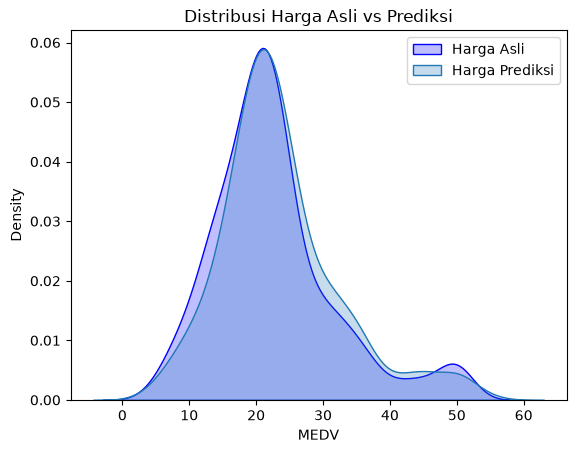

In [9]:
#Dostribusi harga asli vs prediksi
sns.kdeplot(y, label='Harga Asli', color='blue', fill=True)
sns.kdeplot(y_pred, label='Harga Prediksi', color='red', fill=True)
plt.title('Distribusi Harga Asli vs Prediksi')
plt.xlabel('MEDV')
plt.ylabel('Density')
plt.legend()
plt.show()
